# Phase 3: Features + classification (charvi, patient 1)

Regions to classify inside **this member's predicted liver** (region growing, Phase 2):
- **tumour regions** = each blob of the ground-truth tumour mask
- **healthy regions** = dark spots inside the liver that are not tumour (mostly vessels), max 3 per slice

Features: shape + GLCM (0/45/90/135 degrees) + first-order HU statistics. Classifier: **k-nearest neighbours** (k tuned by grouped 5-fold CV).

In [1]:
import os, glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd

NAME = "charvi"
SLICES = f"../data/slices/{NAME}"
ENH = "../phase1/outputs_charvi/enhanced"
LIVER = "../phase2/outputs_charvi/regiongrow"
OUT = "outputs_charvi"
FIGS = "../report/figures/charvi"
os.makedirs(OUT, exist_ok=True)
slice_ids = sorted(os.path.basename(f).replace("_enh.png", "") for f in glob.glob(f"{ENH}/*_enh.png"))
print(len(slice_ids), "slices")

def load(sid):
    return (np.load(f"{SLICES}/{sid}_ct.npy"), cv2.imread(f"{ENH}/{sid}_enh.png", 0),
            cv2.imread(f"{LIVER}/{sid}_liver_pred.png", 0) > 0, cv2.imread(f"{SLICES}/{sid}_tumour.png", 0) > 0)

from scipy.stats import skew, kurtosis
from skimage.measure import regionprops, label
from skimage.feature import graycomatrix, graycoprops

ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]           # 0, 45, 90, 135 degrees
ANGLE_NAMES = ["0", "45", "90", "135"]

def shape_features(mask):
    r = regionprops(mask.astype(np.uint8))[0]
    area, perim = r.area, max(r.perimeter, 1e-6)
    return {"area": area, "perimeter_area_ratio": perim / area,
            "circularity": 4 * np.pi * area / perim ** 2,      # 1 = perfect circle
            "compactness": perim ** 2 / area,
            "eccentricity": r.eccentricity,                      # 0 = circle, 1 = line
            "solidity": r.solidity}                              # area / convex hull area

def glcm_features(enh, mask, levels=32, per_angle=False):
    """GLCM texture inside the region only (pixels outside the region are ignored)."""
    r = regionprops(mask.astype(np.uint8))[0]
    r0, c0, r1, c1 = r.bbox
    patch, m = enh[r0:r1, c0:c1].astype(int), mask[r0:r1, c0:c1]
    q = np.where(m, 1 + patch * (levels - 1) // 255, 0).astype(np.uint8)   # 1..levels inside, 0 outside
    P = graycomatrix(q, distances=[1], angles=ANGLES, levels=levels + 1)[1:, 1:, :, :].astype(float)
    P = P / np.maximum(P.sum(axis=(0, 1), keepdims=True), 1e-12)
    feats = {}
    for prop in ["energy", "contrast", "homogeneity", "correlation"]:
        vals = np.nan_to_num(graycoprops(P, prop)[0])
        feats.update({f"glcm_{prop}_{a}": v for a, v in zip(ANGLE_NAMES, vals)} if per_angle
                     else {f"glcm_{prop}": vals.mean()})
    ent = [-(P[:, :, 0, k][P[:, :, 0, k] > 0] * np.log2(P[:, :, 0, k][P[:, :, 0, k] > 0])).sum() for k in range(4)]
    feats.update({f"glcm_entropy_{a}": v for a, v in zip(ANGLE_NAMES, ent)} if per_angle
                 else {"glcm_entropy": np.mean(ent)})
    return feats

def first_order_features(ct, mask):
    hu = ct[mask].astype(float)
    return {"mean_HU": hu.mean(), "variance_HU": hu.var(),
            "skewness": skew(hu) if hu.std() > 0 else 0.0,
            "kurtosis": kurtosis(hu) if hu.std() > 0 else 0.0}

def glcm_angle_table(enh, mask):
    t = pd.Series(glcm_features(enh, mask, per_angle=True))
    return pd.DataFrame({a: t[[k for k in t.index if k.endswith("_" + a)]].values for a in ANGLE_NAMES},
                        index=["energy", "contrast", "homogeneity", "correlation", "entropy"]).round(3)

18 slices


In [2]:
MIN_AREA, DARK_K = 10, 1.5
rng = np.random.default_rng(42)

def candidate_spots(enh, liver):
    """Dark spots inside the liver: darker than (median - 1.5 x std) of the liver."""
    inner = cv2.erode(liver.astype(np.uint8), np.ones((9, 9), np.uint8)) > 0
    if not inner.any():
        return np.zeros_like(liver)
    dark = (enh < np.median(enh[inner]) - DARK_K * enh[inner].std()) & inner
    return cv2.morphologyEx(dark.astype(np.uint8), cv2.MORPH_OPEN, np.ones((3, 3), np.uint8)) > 0

rois = []
for sid in slice_ids:
    ct, enh, liver, tumour = load(sid)
    for r in regionprops(label(tumour)):
        if r.area >= MIN_AREA:
            m = np.zeros(tumour.shape, bool); m[tuple(r.coords.T)] = True
            rois.append((sid, m, 1))
    healthy = []
    for r in regionprops(label(candidate_spots(enh, liver))):
        m = np.zeros(tumour.shape, bool); m[tuple(r.coords.T)] = True
        if r.area >= MIN_AREA and not (m & tumour).any():
            healthy.append(m)
    for i in rng.permutation(len(healthy))[:3]:
        rois.append((sid, healthy[i], 0))
labels = np.array([y for _, _, y in rois])
print(len(rois), "regions:", (labels == 1).sum(), "tumour,", (labels == 0).sum(), "healthy")

sid, m, _ = next(r for r in rois if r[2] == 1)
print(f"\nGLCM at 4 angles, tumour region in {sid}:")
print(glcm_angle_table(load(sid)[1], m))

glcm_example = glcm_angle_table(load(sid)[1], m)
glcm_example.to_csv(f"{FIGS}/{NAME}_glcm_table.csv")

87 regions: 35 tumour, 52 healthy

GLCM at 4 angles, tumour region in p1_s56:
                 0     45     90    135
energy       0.249  0.255  0.238  0.232
contrast     3.295  4.425  0.382  2.109
homogeneity  0.307  0.228  0.809  0.415
correlation  0.979  0.979  0.983  0.980
entropy      4.272  4.078  4.309  4.355


In [3]:
cache, rows = {}, []
for sid, m, y in rois:
    if sid not in cache:
        cache[sid] = load(sid)
    ct, enh, _, _ = cache[sid]
    rows.append({"slice": sid, "label": y, **shape_features(m), **glcm_features(enh, m), **first_order_features(ct, m)})
features = pd.DataFrame(rows)
features.to_csv(f"{OUT}/phase3_features.csv", index=False)
print(features.groupby("label").mean(numeric_only=True).T.round(3).rename(columns={0: "healthy", 1: "tumour"}))

label                 healthy   tumour
area                  121.750  204.657
perimeter_area_ratio    0.515    0.358
circularity             0.901    0.792
compactness            17.765   17.176
eccentricity            0.752    0.637
solidity                0.894    0.893
glcm_energy             0.587    0.397
glcm_contrast           0.476    0.486
glcm_homogeneity        0.828    0.792
glcm_correlation        0.633    0.783
glcm_entropy            2.095    3.125
mean_HU                88.253   71.705
variance_HU           316.958  234.334
skewness               -0.202    0.075
kurtosis               -0.251   -0.018


In [4]:
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, GridSearchCV, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score
import joblib

X = features.drop(columns=["slice", "label"]).values
y = features["label"].values

# ---- groups: every region from the same slice stays on the same side of the split ----
# Neighbouring slices show the same tumour, so a random split of regions would put near-copies in train AND test.
# Consecutive slices are joined into blocks of 3 (or 2) only if that still leaves >= 5 training groups for 5-fold CV.
slice_no = features["slice"].str.extract(r"_s(\d+)")[0].astype(int)
position = slice_no.map({s: i for i, s in enumerate(sorted(slice_no.unique()))}).values   # 0, 1, 2, ... along the scan
def grouped_split(groups):
    """70/30 split by group. Groups differ in size, so try 50 seeds and keep the one whose test part is closest
    to 30% of the REGIONS (only sizes are looked at, never the scores). Needs >= 5 train groups + both classes in test."""
    best_split, best_gap = None, 1.0
    for seed in range(50):
        tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=seed).split(X, y, groups))
        if len(np.unique(groups[tr])) >= 5 and len(np.unique(y[te])) == 2 and abs(len(te) / len(y) - 0.3) < best_gap:
            best_split, best_gap = (tr, te), abs(len(te) / len(y) - 0.3)
    return best_split

for BLOCK in (3, 2, 1):
    groups = position // BLOCK
    split = grouped_split(groups)
    if split is not None:
        break
idx_train, idx_test = split
X_train, X_test, y_train, y_test = X[idx_train], X[idx_test], y[idx_train], y[idx_test]
print(f"block = {BLOCK} slice(s) per group | train: {len(np.unique(groups[idx_train]))} groups, {len(idx_train)} regions"
      f" | test: {len(np.unique(groups[idx_test]))} groups, {len(idx_test)} regions"
      f" ({len(idx_test) / len(y):.0%} of all regions)")

from sklearn.neighbors import KNeighborsClassifier
# k-NN: a new region gets the majority label of its k closest regions in feature space
# 5-fold grouped cross-validation on the 70% TRAIN part only picks the k; the 30% test part stays untouched
cv5 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
search = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()),
                      {"kneighborsclassifier__n_neighbors": [1, 3, 5, 7, 9]}, cv=cv5, scoring="f1")
search.fit(X_train, y_train, groups=groups[idx_train])
best = search.best_params_["kneighborsclassifier__n_neighbors"]
model = search.best_estimator_                     # already refitted on the whole 70% train part
y_pred = model.predict(X_test)

cv = cross_validate(model, X_train, y_train, groups=groups[idx_train], cv=cv5, scoring=["accuracy", "f1"])
print(f"tuned k = {best}  (tried [1, 3, 5, 7, 9])")
print(f"5-fold grouped CV on train: accuracy {cv['test_accuracy'].mean():.3f} +/- {cv['test_accuracy'].std():.3f}"
      f"  folds: {np.round(cv['test_accuracy'], 3)}")
print(f"                            F1       {cv['test_f1'].mean():.3f} +/- {cv['test_f1'].std():.3f}"
      f"  folds: {np.round(cv['test_f1'], 3)}")
cv_summary = {"tuned k": best, "group block (slices)": BLOCK,
              "CV accuracy mean": cv["test_accuracy"].mean(), "CV accuracy std": cv["test_accuracy"].std(),
              "CV F1 mean": cv["test_f1"].mean(), "CV F1 std": cv["test_f1"].std()}

block = 2 slice(s) per group | train: 6 groups, 61 regions | test: 3 groups, 26 regions (30% of all regions)


tuned k = 1  (tried [1, 3, 5, 7, 9])
5-fold grouped CV on train: accuracy 0.771 +/- 0.115  folds: [0.727 0.7   0.727 0.7   1.   ]
                            F1       0.750 +/- 0.129  folds: [0.75  0.667 0.667 0.667 1.   ]


Test set: 26 regions (10 tumour, 16 healthy)
  accuracy               0.731
  sensitivity (recall)   0.900
  specificity            0.625
  F1                     0.720


95% bootstrap CI (test groups resampled):
  accuracy               [0.571, 0.800]
  sensitivity (recall)   [0.667, 1.000]
  specificity            [0.400, 0.833]
  F1                     [0.571, 0.833]


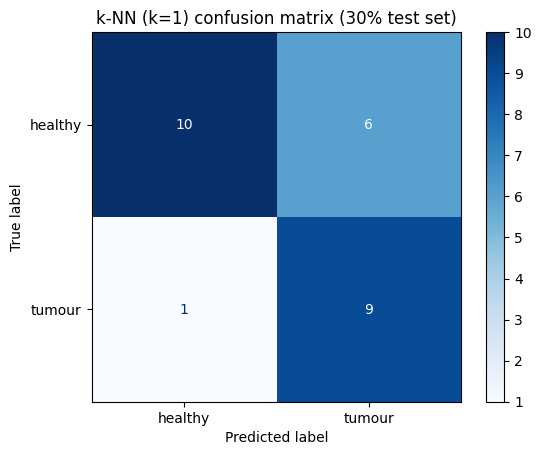

In [5]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
metrics = {"accuracy": accuracy_score(y_test, y_pred),
           "sensitivity (recall)": tp / (tp + fn) if tp + fn else 0,   # tumours correctly found
           "specificity": tn / (tn + fp) if tn + fp else 0,            # healthy correctly cleared
           "F1": f1_score(y_test, y_pred, zero_division=0)}
print(f"Test set: {len(y_test)} regions ({(y_test == 1).sum()} tumour, {(y_test == 0).sum()} healthy)")
for k, v in metrics.items():
    print(f"  {k:22s} {v:.3f}")
# ---- 95% confidence intervals: bootstrap over the test GROUPS (slices), 2000 resamples ----
def scores(t, p):
    tn, fp, fn, tp = confusion_matrix(t, p, labels=[0, 1]).ravel()
    return [accuracy_score(t, p), tp / (tp + fn) if tp + fn else np.nan, tn / (tn + fp) if tn + fp else np.nan,
            f1_score(t, p, zero_division=0)]
boot_rng = np.random.default_rng(0)
test_groups = groups[idx_test]
boot = []
for _ in range(2000):
    pick = np.concatenate([np.where(test_groups == g)[0] for g in boot_rng.choice(np.unique(test_groups), len(np.unique(test_groups)))])
    boot.append(scores(y_test[pick], y_pred[pick]))
lo, hi = np.nanpercentile(boot, 2.5, axis=0), np.nanpercentile(boot, 97.5, axis=0)
ci = {}
print("95% bootstrap CI (test groups resampled):")
for k, a, b in zip(metrics, lo, hi):
    ci[f"{k} CI low"], ci[f"{k} CI high"] = a, b
    print(f"  {k:22s} [{a:.3f}, {b:.3f}]")
pd.DataFrame([{**metrics, **cv_summary, **ci}]).to_csv(f"{OUT}/phase3_metrics.csv", index=False)

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=[0, 1]),
                       display_labels=["healthy", "tumour"]).plot(cmap="Blues")
plt.title(f"k-NN (k={best}) confusion matrix (30% test set)")
plt.savefig(f"{FIGS}/{NAME}_p3_confusion_matrix.png", dpi=120, bbox_inches="tight"); plt.show()

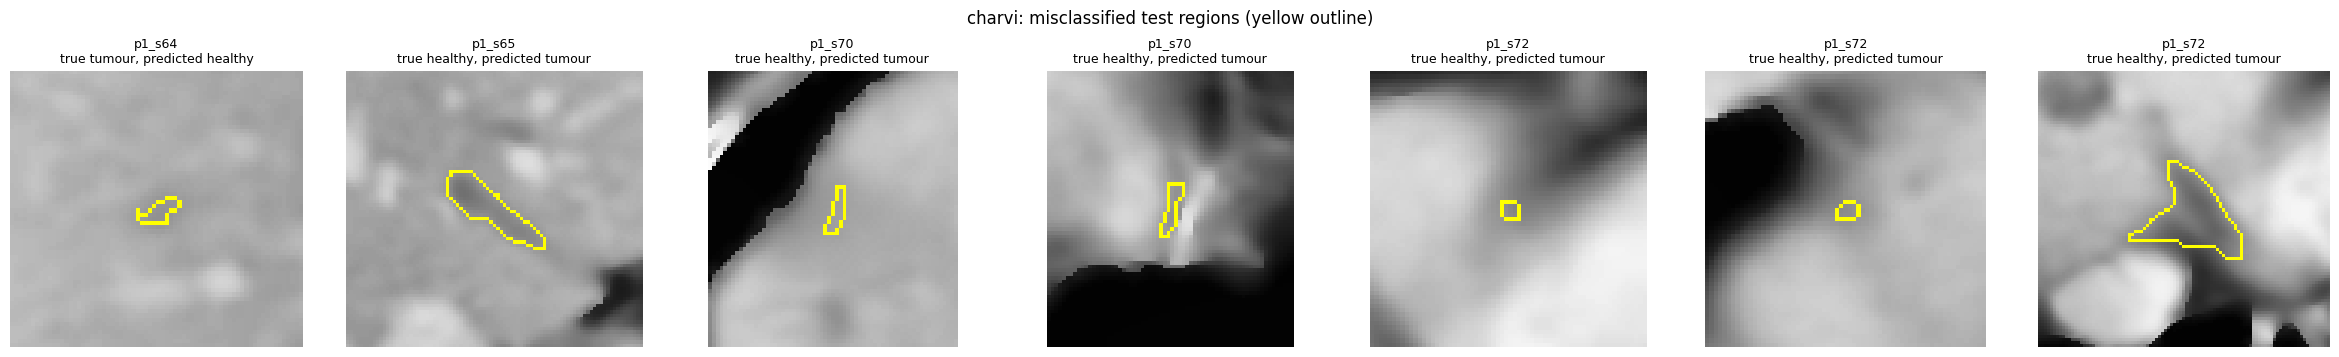

# Phase 3 failed cases: charvi

Test set: 26 regions, **7 misclassified**.

| Slice | True | Predicted | Area (px) | Mean HU | Likely reason |
|---|---|---|---|---|---|
| p1_s64 | tumour | healthy | 47 | 92 | tumour region too small to measure shape/texture reliably |
| p1_s65 | healthy | tumour | 291 | 92 | healthy dark structure (vessel or organ edge) that looks tumour-like |
| p1_s70 | healthy | tumour | 50 | 79 | healthy dark structure (vessel or organ edge) that looks tumour-like |
| p1_s70 | healthy | tumour | 60 | 35 | healthy dark structure (vessel or organ edge) that looks tumour-like |
| p1_s72 | healthy | tumour | 23 | 63 | healthy dark structure (vessel or organ edge) that looks tumour-like |
| p1_s72 | healthy | tumour | 25 | 65 | healthy dark structure (vessel or organ edge) that looks tumour-like |
| p1_s72 | healthy | tumour | 589 | 54 | healthy dark structure (vessel or organ edge) that looks tumour-like |


In [6]:
# ---- failed cases: the test regions the classifier got wrong ----
FAILED = f"../report/failed_cases/{NAME}"
os.makedirs(FAILED, exist_ok=True)
wrong = idx_test[y_pred != y_test]
names = {0: "healthy", 1: "tumour"}
lines = [f"# Phase 3 failed cases: {NAME}", "",
         f"Test set: {len(y_test)} regions, **{len(wrong)} misclassified**.", "",
         "| Slice | True | Predicted | Area (px) | Mean HU | Likely reason |", "|---|---|---|---|---|---|"]
for i in wrong:
    sid, m, true = rois[i]
    row = features.iloc[i]
    if true == 1 and row["area"] < 100:
        why = "tumour region too small to measure shape/texture reliably"
    elif true == 1:
        why = "tumour looks like normal liver (similar brightness/texture)"
    else:
        why = "healthy dark structure (vessel or organ edge) that looks tumour-like"
    lines.append(f"| {sid} | {names[true]} | {names[1 - true]} | {int(row['area'])} | {row['mean_HU']:.0f} | {why} |")
if len(wrong):
    fig, axes = plt.subplots(1, len(wrong), figsize=(3.4 * len(wrong), 3.6), squeeze=False)
    for a, i in zip(axes[0], wrong):
        sid, m, true = rois[i]
        rgb = cv2.cvtColor(load(sid)[1], cv2.COLOR_GRAY2RGB)
        contours, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(rgb, contours, -1, (255, 255, 0), 1)
        ys, xs = np.where(m)
        y0, y1, x0, x1 = max(ys.min() - 30, 0), ys.max() + 30, max(xs.min() - 30, 0), xs.max() + 30
        a.imshow(rgb[y0:y1, x0:x1]); a.axis("off")
        a.set_title(f"{sid}\ntrue {names[true]}, predicted {names[1 - true]}", fontsize=9)
    plt.suptitle(f"{NAME}: misclassified test regions (yellow outline)")
    plt.tight_layout(); plt.savefig(f"{FAILED}/{NAME}_p3_misclassified.png", dpi=120, bbox_inches="tight"); plt.show()
else:
    lines.append("| - | - | - | - | - | no mistakes in this test split |")
open(f"{FAILED}/{NAME}_phase3_failed_cases.md", "w").write("\n".join(lines))
print("\n".join(lines))

In [7]:
model.fit(X, y)
joblib.dump({"model": model, "feature_names": list(features.columns[2:])}, f"{OUT}/knn_model.joblib")
print("saved model to", f"{OUT}/knn_model.joblib")

saved model to outputs_charvi/knn_model.joblib
